In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

'/projectnb/batmanlab/mragoza/lung-project/notebooks/IPMI-2027'

In [2]:
import sys, os

def add_path(path):
    if path not in sys.path:
        sys.path.append(path)

add_path(os.environ['LP_ROOT'])
import project

add_path(os.environ['PROJECT'] + '/' + 'param_search')
import param_search as ps

import torch

ps.set_backend('sge')
ps.set_verbose(False)

torch.cuda.is_available()

True

In [19]:
optim_method = 'Baseline'
train_method = 'Ours'

def load_optim_jobs(base_dir, *group_keys):
    index_cols = [*group_keys, 'params.subject']
    return ps.load(base_dir).set_index(index_cols, verify_integrity=True)

def load_train_jobs(base_dir, *group_keys):
    index_cols = [*group_keys, 'params.random_seed']
    return ps.load(base_dir).set_index(index_cols, verify_integrity=True)

def load_optim_metrics(jobs):
    return ps.outputs(
        jobs.reset_index(),
        meta_cols=['base_dir', 'job_name', 'job_id'],
        output_name='outputs/optimize/default/eval_metrics.csv',
        read_csv_kws={'index_col': 0},
        skip_errors=True
    )

def load_train_metrics(jobs):
    return ps.outputs(
        jobs.reset_index(),
        meta_cols=['base_dir', 'job_name', 'job_id'],
        output_name='outputs/training/default/eval_metrics.csv',
        skip_errors=True
    )


def select_best_epoch(metrics, group_keys, by='loss'):
    # select best training (seed, epoch) by validation loss
    epoch_keys = list(group_keys) + ['params.random_seed', 'epoch']
    epoch_scores = (
        metrics.query('phase == "val"')
        .groupby(epoch_keys)[by].mean()
        .reset_index()
    )
    best_epochs = epoch_scores.loc[
        epoch_scores.groupby(group_keys)[by].idxmin()
    ]
    best_lookup = (
        best_epochs
        .set_index(group_keys, verify_integrity=True)
    )
    
    # filter train metrics to best (seed, epoch) per protocol
    best_metrics = metrics.merge(
        best_epochs[epoch_keys],
        on=epoch_keys,
        how='inner',
        validate='many_to_one'
    )
    return best_metrics, best_lookup

def concat_methods(train, optim, phase, split):
    import pandas as pd
    train_sel = train['phase'].eq(phase)
    optim_sel = optim['params.subject'].isin(split[phase])
    result = pd.concat([
        train[train_sel].assign(method=train_method),
        optim[optim_sel].assign(method=optim_method)
    ], ignore_index=True)
    return result


# Phantom reconstruction

In [20]:
subj_split = {
    'train': ['10049K', '10056H', '10081G', '10096T', '10114V', '10124Y', '10127E', '10130T', '10153F', '10155J', '10179X', '10181K', '10196X', '10211T', '10212V', '10213X', '10217F', '10227I', '10233D', '10245K', '10261I', '10265Q', '10301U', '10314D', '10328O', '10332F', '10367Y', '10372R', '10395D', '10426O', '10458B', '10469G', '10481W', '10502E', '10503G', '10507O', '10512H', '10523M', '10524O', '10539B', '10552T', '10560S', '10561U', '10564A', '10566E', '10567G', '10572Z', '10624S', '10635X', '10641S', '10646C', '10663C', '10679R', '10699X', '10705S', '10724W', '10736D', '10761C', '10794R', '10815Z', '10829K', '10842C', '10843E', '10883Q', '10887Y', '10888A', '10908G', '10919L', '10947Q', '10961K', '10973R', '10975V', '10990R', '11005V', '11007Z', '11027F', '11049P', '11063J', '11085T', '11114A', '11120V', '11123B', '11139Q', '11153K', '11193W', '11198G', '11211Y', '11221B', '11224H', '11225J', '11226L', '11235M', '11240F', '11247T', '11260L', '11267Z', '11281T', '11329V', '11350M', '11363V', '11404J', '11455A', '11468J', '11477K', '11498S', '11506R', '11514Q', '11516U', '11545B', '11560X', '11600J', '11613S', '11616Y', '11618C', '11676Q', '11690K', '11708D', '11713W', '11716C', '11721V', '11743F', '11746L', '11752G', '11782P', '11783R', '11815E', '11819M', '11828N', '11830A', '11850G', '11852K', '11858W', '11866V', '11879E', '11881R', '11901X', '11903B', '11943N', '11947V', '11972U', '11998M', '12052J', '12069A', '12146S', '12187G', '12231J', '12294H', '12339D', '12362Y', '12418Z', '12457J', '12466K', '12477P', '12478R', '12515X', '12516Z', '12519F', '12560C', '12599D', '12607C', '12608E', '12651F', '12676V', '12683S', '12696B', '12816L', '12825M', '12831H', '12851N', '12878H', '12895H', '12903G', '12905K', '12962W', '12964A', '13034M', '13053Q', '13065X', '13071S', '13084B', '13092A', '13093C', '13103F', '13111E', '13149D', '13170U', '13242T', '13248F', '13267J', '13273E', '13282F', '13297S', '13301J', '13340T', '13341V', '13350W', '13354E', '13358M', '13365J', '13370C', '13383L', '13384N', '13398Y', '13404T', '13407Z', '13419G', '13428H', '13460D', '13488Z', '13489B', '13498C', '13501R', '13507D', '13517G', '13528L', '13542F', '13563N', '13586Z', '13632G', '13651K', '13682V', '13686D', '13702B', '13704F', '13719S', '13728T', '13736S', '13767D', '13780V', '13816Q', '13845X', '13864B', '13866F', '13901H', '13916U', '13925V', '13945B', '13947F', '13998W', '14013J', '14031L', '14047A', '14075F', '14084G', '14113N', '14121M', '14133T', '14157H', '14173F', '14180C', '14194N', '14201K', '14217Z', '14232V', '14241W', '14257L', '14278T', '14293P', '14307A', '14309E', '14329K', '14332Z', '14386W', '14390N', '14417H', '14462M', '14471N', '14508K', '14525K', '14526M', '14632L', '14633N', '14646W', '14668G', '14683C', '14684E', '14685G', '14704K', '14705M', '14729A', '14732P', '14771Z', '14774F', '14814R', '14817X', '14834X', '14845C', '14857J', '14863E', '14875L', '14880E', '14909C', '14964K', '14987W', '14991N', '15040R', '15073G', '15075K', '15078Q', '15082H', '15088T', '15102N', '15140V', '15152C', '15156K', '15163H', '15164J', '15165L', '15204V', '15212U', '15217E', '15221V', '15224B', '15232A', '15237K', '15262J', '15271K', '15297C', '15312Y', '15349V', '15350G', '15357U', '15384X', '15450K', '15473W', '15488J', '15489L', '15502D', '15527T', '15532M', '15537W', '15549D', '15607R', '15623P', '15635W', '15650S', '15661X', '15690E', '15699W', '15745D', '15799A', '15807Z', '15811Q', '15827F', '15840X', '15848N', '15885T', '15894U', '15900P', '15909H', '15911U', '15929N', '15934G', '15965R', '16021S', '16045G', '16059R', '16060C', '16065M', '16069U', '16091N', '16118H', '16266W', '16300W', '16347W', '16353R', '16402E', '16411F', '16440M', '16472Z', '16527Y', '16540Q', '16573F', '16605S', '16637F', '16675N', '16700M', '16716B', '16747M', '16783Q', '16853L', '16954R', '16977D', '17011U', '17022Z', '17041D', '17089F', '17104B', '17137Q', '17144N', '17173U', '17212E', '17233M', '17255W', '17266B', '17337Y', '17366F', '17385J', '17409X', '17414Q', '17428B', '17433U', '17461Z', '17473G', '17505T', '17509B', '17557M', '17573K', '17617E', '17629L', '17696A', '17722B', '17757U', '17790S', '17836Q', '17847V', '17862R', '17894E', '17897K', '17920F', '17922J', '17939A', '17952S', '17955Y', '17995K', '18015H', '18043M', '18103E', '18126Q', '18140K', '18153T', '18184E', '18278N', '18317X', '18374J', '18395R', '18403Q', '18434B', '18451B', '18452D', '18505Y', '18515B', '18525E', '18553J', '18563M', '18629Q', '18633H', '18674V', '18677B', '18682U', '18687E', '18703C', '18761Q', '18786G', '18798N', '18801C', '18830J', '18845W', '18935X', '18960W', '18982G', '19049D', '19059G', '19091C', '19139E', '19143V', '19251Y', '19324Z', '19339M', '19356M', '19367R', '19396Y', '19410S', '19415C', '19478A', '19549X', '19558Y', '19560L', '19594C', '19598K', '19612E', '19637U', '19666B', '19673Y', '19679K', '19760T', '19783F', '19784H', '19785J', '19819A', '19839G', '19849J', '19880D', '19908Z', '19913S', '19922T', '19950Y', '20005W', '20006Y', '20019H', '20024A', '20064M', '20088A', '20102U', '20117H', '20149U', '20188E', '20195B', '20245Q', '20286E', '20306K', '20332L', '20349C', '20378J', '20385G', '20453X', '20519B', '20566K', '20589W', '20592L', '20609C', '20623W', '20632X', '20640W', '20668S', '20678V', '20682M', '20689A', '20703U', '20738N', '20748Q', '20792T', '20803Y', '20807G', '20867Y', '20901Y', '20970R', '20976D', '20977F', '21004Z', '21010U', '21012Y', '21042H', '21052K', '21065T', '21106H', '21150K', '21163T', '21168D', '21175A', '21176C', '21189L', '21223L', '21224N', '21272Y', '21279M', '21293G', '21384J', '21391G', '21398U', '21399W', '21410K', '21419C', '21433W', '21438G', '21461B', '21467N', '21469R', '21484N', '21494Q', '21508B', '21521T', '21526D', '21538K', '21556M', '21559S', '21572K', '21586V', '21587X', '21595W', '21604X', '21611U', '21614A', '21622Z', '21640B', '21647P', '21660H', '21741H', '21769D', '21778E', '21800X', '21813G', '21837U', '21844R', '21850M', '21877G', '21886H', '21897M', '21899Q', '21933Q', '21968J', '22002A', '22055V', '22078H', '22114L', '22116P', '22148C', '22193H', '22210H', '22224S', '22253Z', '22261Y', '22308Y', '22312P', '22325Y', '22357L', '22389Y', '22423Y', '22464M', '22483Q', '22484S', '22487Y', '22495X', '22497B', '22536L', '22592V', '22597F', '22600U', '22604C', '22617L', '22637R', '22663S', '22678F', '22726Q', '22736T', '22745U', '22746W', '22759F', '22827W', '22832P', '22855B', '22877L', '22891F', '22912N', '22920M', '22928C', '22946E', '22961A', '22986Q', '23023N', '23037Y', '23052U', '23074E', '23075G', '23091E', '23094K', '23108V', '23123R', '23124T', '23136A', '23150U', '23155E', '23165H', '23193M', '23239K', '23252C', '23266N', '23269T', '23284P', '23287V', '23293Q', '23310Q', '23326F', '23342D', '23436M', '23500V', '23526N', '23549Z', '23558A', '23574Y', '23577E', '23618S', '23636U', '23656A', '23657C', '23699S', '23705N', '23725T', '23743V', '23746B', '23799W', '23803N', '23816W', '23819C', '23821P', '23851Y', '23902P', '23934C', '24064G', '24080E', '24106W', '24113T', '24123W', '24137H', '24151B', '24154H', '24181K', '24186U', '24205Y', '24213X', '24271L', '24318L', '24331D', '24348U', '24350H', '24383W', '24390T', '24394B', '24438V', '24447W', '24449A', '24480U', '24514L', '24576H', '24581A', '24608U', '24638D', '24646C', '24652X', '24679R', '24682G', '24684K', '24691H', '24699X', '24705S', '24711N', '24714T', '24744C', '24757L', '24761C', '24763G', '24777R', '24810P', '24830V', '24867S', '24873N', '24911V', '24927K', '24950F', '24954N', '24989G', '25003R', '25007Z', '25051C', '25072K', '25096Y', '25120V', '25125F', '25130Y', '25231E', '25245P', '25276A', '25303D', '25309P', '25311C', '25328T', '25335Q', '25347X', '25360P', '25380V', '25381X', '25388L', '25389N', '25400B', '25407P', '25410E', '25454Y', '25552Y', '25601L', '25602N', '25674M', '25703T', '25728J', '25762J', '25767T', '25782P', '25888F', '25894A', '25900V', '25914G', '25923H', '25926N', '25943N', '25950K', '25991Y', '26004Y', '26012X', '26146S'],
    'test': ['10432J', '10490X', '10568I', '10571X', '10634V', '10709A', '10728E', '10880K', '11255S', '11353S', '11542V', '11750C', '12139V', '12147U', '12273Z', '12422Q', '12506W', '12593R', '12630X', '12795D', '12812D', '12861Q', '13264D', '13477U', '13573Q', '13799Q', '14374P', '14788Q', '14905U', '15272M', '15413E', '15617U', '15905Z', '16058P', '16064K', '16142E', '16277B', '16390X', '16463Y', '16514P', '17102X', '17247X', '17476M', '17904H', '18274F', '18341U', '18351X', '18498B', '18593V', '18714H', '18736R', '18808Q', '18886K', '18940Q', '19024N', '19393S', '19627R', '19686H', '19730K', '19912Q', '19921R', '20008C', '20296H', '20400C', '20529E', '20543Y', '20696X', '21170Q', '21534C', '21615C', '21679C', '21838W', '21892C', '22031H', '22113J', '22151R', '22198R', '22430V', '22667A', '22873D', '22914R', '22983K', '23077K', '23312U', '23615M', '23838G', '23930U', '23940X', '24269Y', '24279B', '24431H', '24887Y', '24973R', '25165R', '25320D', '25403H', '25704V', '25835K', '26066U', '26112B'],
    'val': ['10017X', '10020M', '10031R', '10478H', '10806Y', '10817D', '10849Q', '11099E', '11181P', '11195A', '11292Y', '11325N', '11440N', '11512M', '11556G', '11968D', '12223K', '12248A', '12336X', '13255C', '13530Y', '13533E', '13578A', '13648V', '14240U', '14261C', '14330V', '14380K', '14550J', '14745Y', '14754Z', '14837D', '14924Y', '15072E', '15132W', '15267T', '15319M', '15424J', '15606P', '15898C', '16076R', '16128K', '16132B', '16216H', '16294B', '16537B', '16546C', '16613R', '16823C', '17533Y', '17688B', '18364G', '18397V', '18519J', '18840M', '18871X', '19027T', '19056A', '19096M', '19429N', '19579G', '19733Q', '19887R', '20151H', '20375D', '20412J', '20435V', '20622U', '20659R', '20770J', '20818L', '20981W', '21064R', '21083V', '21153Q', '21765V', '21842N', '22092B', '22135T', '22170V', '22182C', '22348K', '22504Y', '22566U', '22720E', '23011G', '23181F', '23741R', '24012N', '24059N', '24116Z', '24377B', '24396F', '24562W', '24643W', '25205D', '25310A', '25694S', '25695U', '26071N'],
}

In [21]:
protocol_keys = ['params.forward_mat', 'params.inverse_mat']
material_types = ['LE', 'NH']

optim_jobs = load_optim_jobs('../copdgene/2026-10-30_optimize', *protocol_keys).loc[material_types, :]
train_jobs = load_train_jobs('../copdgene/2026-10-30_train', *protocol_keys).loc[material_types, :]

optim_metrics = load_optim_metrics(optim_jobs)
train_metrics = load_train_metrics(train_jobs)

100%|██████████| 9/9 [00:00<00:00, 32.79it/s]


In [23]:
best_metrics, best_lookup = select_best_epoch(
    train_metrics, protocol_keys, by='loss'
)
best_lookup

params.random_seed  epoch      loss
params.forward_mat params.inverse_mat                                     
LE                 LE                                   0     10  0.000257
NH                 LE                                   2     10  0.000830
                   NH                                   0     10  0.000318

In [29]:
# concat evaluation metrics to compare methods
eval_phase = 'test'

compare_metrics = concat_methods(
    best_metrics,
    optim_metrics,
    eval_phase,
    subj_split
)

In [30]:
# recover missing subject IDs from unique voxel counts

subj_lookup = optim_metrics[['num_voxels', 'params.subject']] \
    .drop_duplicates() \
    .set_index('num_voxels', verify_integrity=True)['params.subject']

compare_metrics['subject'] = compare_metrics['num_voxels'].map(subj_lookup)

compare_metrics['protocol'] = (
    compare_metrics['params.forward_mat'] + ' → ' +
    compare_metrics['params.inverse_mat']
)

subj_lookup

num_voxels
4088362    10017X
3703108    10020M
4398155    10031R
3262363    10478H
4601201    10806Y
            ...  
2347183    25403H
5568392    25704V
4373385    25835K
2513958    26066U
2943106    26112B
Name: params.subject, Length: 200, dtype: object

In [31]:
# aggregate metrics across subjects
from scipy.stats import iqr

metric_keys = ['u_cell.nrmse', 'E_cell.nrmse', 'E_cell.scorr']
group_keys = ['protocol', 'method']

compare_metrics.groupby(group_keys)[metric_keys] \
    .agg(['count', 'mean', 'std', 'median', iqr])

u_cell.nrmse                                          \
                         count      mean       std    median       iqr   
protocol method                                                          
LE → LE  Baseline          100  0.003994  0.008357  0.002630  0.001026   
         Ours              100  0.018589  0.014151  0.015517  0.008098   
NH → LE  Baseline          100  0.008460  0.004018  0.007691  0.003513   
         Ours              100  0.035640  0.022250  0.031950  0.013909   
NH → NH  Baseline           96  0.003016  0.001464  0.002610  0.000964   
         Ours              100  0.020598  0.013088  0.017761  0.009481   

                  E_cell.nrmse                                          \
                         count      mean       std    median       iqr   
protocol method                                                          
LE → LE  Baseline          100  0.237114  0.107674  0.217893  0.138389   
         Ours              100  0.154300  0.052602  0.144083  0.073157   
NH → LE  Baseline          100  0.556983  0.615098  0.323241  0.279895   
         Ours              100  0.442401  0.137086  0.416972  0.176097   
NH → NH  Baseline           96  0.231124  0.098841  0.217598  0.133867   
         Ours              100  0.181212  0.060819  0.167837  0.073445   

                  E_cell.scorr                                          
                         count      mean       std    median       iqr  
protocol method                                                         
LE → LE  Baseline          100  0.845339  0.172275  0.900221  0.080811  
         Ours              100  0.901273  0.065234  0.914998  0.050696  
NH → LE  Baseline          100  0.779042  0.147255  0.817496  0.128768  
         Ours              100  0.861120  0.077416  0.883522  0.082309  
NH → NH  Baseline           96  0.866502  0.124076  0.905920  0.089827  
         Ours              100  0.884957  0.071039  0.906081  0.066851

In [32]:
# configure labels and order for plotting

readable_names = {
    'E_vox.nrmse': '$E$ normalized RMSE',
    'E_vox.pcorr': '$E$ Pearson correlation',
    'E_vox.scorr': '$E$ rank correlation',
    'E_cell.nrmse': '$E$ normalized RMSE',
    'E_cell.pcorr': '$E$ Pearson correlation',
    'E_cell.scorr': '$E$ rank correlation',
    'u_cell.nrmse': '$u$ normalized RMSE',
}
protocol_order = ['LE → LE', 'NH → NH', 'NH → LE']

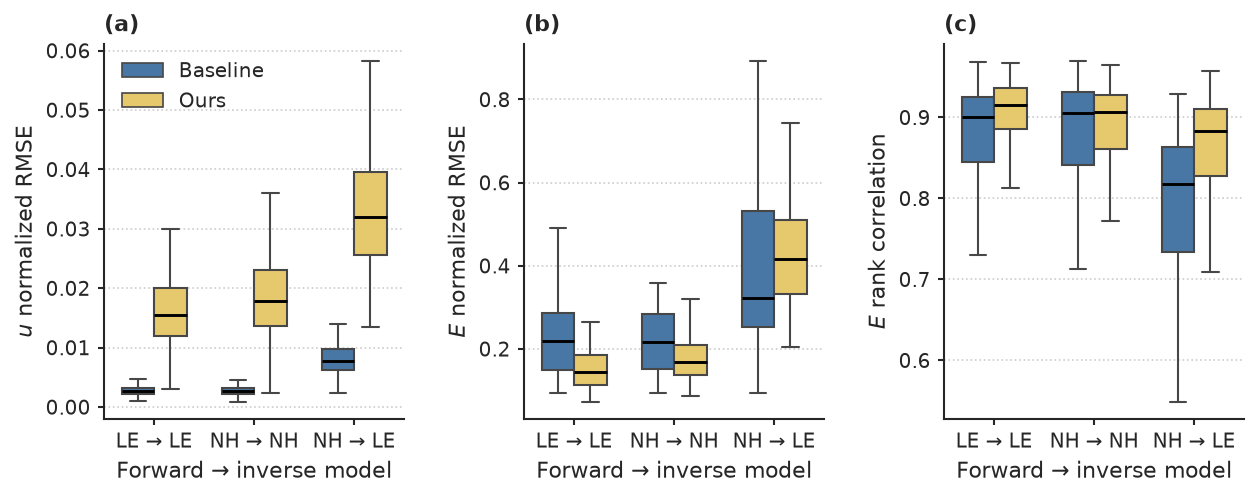

In [33]:
import matplotlib.pyplot as plt
import project.visual.matplotlib as mpl_viz
import seaborn as sns

sns.set_theme(style='ticks', context='paper', font_scale=1.1)
palette = {'Baseline': '#4477AA', 'Ours': '#EECC66'}

fig, axes = mpl_viz.subplot_grid(
    n_rows=1,
    n_cols=3,
    ax_height=2.5,
    ax_width=2,
    spacing=0.8,
    padding=(1.0, 0.5, 1.0, 0.5)
)

metric_keys = ['u_cell.nrmse', 'E_cell.nrmse', 'E_cell.scorr']

for col, metric in enumerate(metric_keys):
    ax = axes[0, col]

    sns.boxplot(
        data=compare_metrics,
        x='protocol',
        y=metric,
        hue='method',
        order=protocol_order,
        hue_order=[optim_method, train_method],
        palette=palette,
        saturation=0.9,
        width=0.65,
        showfliers=False,
        medianprops={'color': 'black', 'linewidth': 1.4},
        ax=ax
    )
    
    ax.set_xlabel('Forward → inverse model')
    ax.set_ylabel(readable_names[metric])
    ax.set_title(f'({chr(97 + col)})', loc='left', fontweight='bold')
    ax.grid(axis='y', linestyle=':')
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', length=3)
    sns.despine(ax=ax)

    ax.get_legend().remove()

handles, labels = axes[0,0].get_legend_handles_labels()
axes[0,0].legend(handles, labels, frameon=False, ncols=1, loc='upper left')

#axes[0,0].set_ylim(0.0, 0.125)
#axes[0,1].set_ylim(0.0, 1.25)
#axes[0,2].set_ylim(-0.125, 1.0)

fig

In [34]:
#fig.savefig('phantom_results_plot.png', bbox_inches='tight', dpi=400)
#fig.savefig('phantom_results_plot.pdf', bbox_inches='tight', dpi=400)

In [35]:
# Subjects and rows contributing to each box
display(
    compare_metrics.groupby(['protocol', 'method']).agg(
        subjects=('subject', 'nunique'),
        rows=('subject', 'size'),
    )
)

subjects  rows
protocol method                  
LE → LE  Baseline       100   100
         Ours           100   100
NH → LE  Baseline       100   100
         Ours           100   100
NH → NH  Baseline        96    96
         Ours           100   100

In [38]:
#fig.savefig('2026-11-05_phantom_grid.png', bbox_inches='tight', dpi=400)
#fig.savefig('2026-11-05_phantom_grid.pdf', bbox_inches='tight', dpi=400)

# BMC-4DCT clinical evaluation

In [119]:
case_split = {
    'train': ['4DCT_10_1', '4DCT_1_1', '4DCT_2_1', '4DCT_2_2', '4DCT_4_1', '4DCT_6_1', '4DCT_7_3', '4DCT_8_1', '4DCT_8_2', 'unknown_12_1', 'unknown_13_1', 'unknown_14_1', 'unknown_16_1', 'unknown_20_1', 'unknown_23_1', 'unknown_26_1', 'unknown_32_1', 'unknown_34_1', 'unknown_36_1', 'unknown_37_1', 'unknown_38_1', 'unknown_42_1', 'unknown_42_4', 'unknown_44_1', 'unknown_45_1', 'unknown_49_1', 'unknown_50_1', 'unknown_52_1', 'unknown_53_1'],
    'test': ['unknown_17_1', 'unknown_17_3', 'unknown_28_1', 'unknown_29_1', 'unknown_30_1', 'unknown_31_1', 'unknown_33_1', 'unknown_43_1', 'unknown_47_1'],
    'val': ['unknown_15_1', 'unknown_18_1', 'unknown_19_1', 'unknown_22_1', 'unknown_27_1', 'unknown_39_1', 'unknown_40_1', 'unknown_40_5', 'unknown_51_1'],
}

In [120]:
protocol_keys = ['params.curr_phase', 'params.material_type']

optim_jobs = load_optim_jobs('../bmc-4dct/2026-11-15_optimize', *protocol_keys)
train_jobs = load_train_jobs('../bmc-4dct/2026-11-15_train', *protocol_keys)

optim_metrics = load_optim_metrics(optim_jobs)
train_metrics = load_train_metrics(train_jobs)

100%|██████████| 54/54 [00:00<00:00, 151.73it/s]


In [121]:
best_metrics, best_lookup = select_best_epoch(
    train_metrics, protocol_keys, by='loss'
)
best_lookup

params.random_seed  epoch      loss
params.curr_phase params.material_type                                     
0                 LE                                     0     23  0.041524
                  NH                                     0     16  0.040917
10                LE                                     0     23  0.059343
                  NH                                     0     25  0.059857
20                LE                                     0     23  0.098553
                  NH                                     0     23  0.099973
30                LE                                     0     21  0.136889
                  NH                                     0     25  0.137764
40                LE                                     0     14  0.217935
                  NH                                     0     16  0.219170
60                LE                                     2     12  0.209306
                  NH                                     0     19  0.206970
70                LE                                     2     17  0.139587
                  NH                                     0     20  0.141967
80                LE                                     2     23  0.078943
                  NH                                     2     23  0.078859
90                LE                                     0     19  0.040631
                  NH                                     2     19  0.040005

In [108]:
# concat evaluation metrics to compare methods
eval_phase = 'train'

compare_metrics = concat_methods(
    best_metrics,
    optim_metrics,
    eval_phase,
    case_split
)

In [109]:
# recover missing case IDs from unique voxel counts

case_lookup = optim_metrics[['num_voxels', 'params.subject']] \
    .drop_duplicates() \
    .set_index('num_voxels', verify_integrity=True)['params.subject']

compare_metrics['subject'] = compare_metrics['num_voxels'].map(case_lookup)
compare_metrics['phase'] = compare_metrics['params.curr_phase']

has_subject = compare_metrics['subject'].notna()
if not has_subject.all():
    print(f'WARNING: {(~has_subject).sum()} rows have unresolved case IDs', file=sys.stderr)


In [110]:
from pathlib import Path
from collections import OrderedDict

def resolve_bmc_config(case_list, curr_phase, material_type, tv_reg_weight=1e-4):
    config = project.fileio.load_config('../bmc-4dct/2026-11-01_config.yaml')
    
    config['dataset']['variant'] = '2026-11-01'
    config['dataset']['subjects'] = case_list
    config['dataset']['state_pairs'] = [(50, curr_phase)]
    config['dataset']['pipeline_tags']['image_registration'] = 'gil'
    config['dataset']['pipeline_tags']['material_properties'] = 'const'
    config['dataset']['pipeline_tags']['field_interpolation'] = 'int'
    
    config['training']['split']['method'] = None
    config['training']['loaders']['shuffle'] = False
    config['training']['loaders']['batch_size'] = 1
    
    config['training']['pde_solver']['material_type'] = material_type
    config['training']['pde_solver']['tv_reg_weight'] = tv_reg_weight

    config['optimization']['pde_solver']['material_type'] = material_type
    config['optimization']['pde_solver']['tv_reg_weight'] = tv_reg_weight

    return config

# evaluate specific protocol
curr_phase = 0
material_type = 'LE'

protocol_vals = (curr_phase, material_type)

case_ids = case_split[eval_phase]
config = resolve_bmc_config(case_ids, *protocol_vals)
examples = project.get_examples(config['dataset'])

Loading ../bmc-4dct/2026-11-01_config.yaml
Gathering examples...
29 total


In [115]:
from collections import defaultdict
import numpy as np

def load_baseline(optim_job):
    output_dir = Path(optim_jobs.loc[*args, case_id].work_dir) / 'outputs'
    path = output_dir / 'optimize' / 'default' / case_id / 'rasters' / 'E_pred.nii.gz'
    return project.fileio.load_nibabel(path).get_fdata(dtype=np.float32)

def load_trainer(case_ids, *args):
    import project.training
    best = best_lookup.loc[*args]
    best_seed = best['params.random_seed']
    output_dir = Path(train_jobs.loc[*args, best_seed].work_dir) / 'outputs'
    config = resolve_bmc_config(case_ids, *args)
    examples = project.get_examples(config['dataset'])
    trainer = project.training.get_trainer(
        examples, config['training'], output_dir=output_dir, device='cuda'
    )
    trainer.load_checkpoint(epoch=int(best.epoch))
    return trainer

def run_inference(trainer, batch):
    outputs = trainer.run_batch(batch, eval_mode=True)
    return outputs['preds']['E'][0,0].detach().cpu().numpy()



In [ ]:
best = best_lookup.loc[*protocol_vals]

trainer = load_trainer(case_ids, *protocol_vals)

In [118]:
%%time
E_optim, E_train = {}, {}



for batch in trainer.train_loader:
    case_id = batch['example'][0].subject
    optim_job = optim_jobs.loc[*protocol_vals, case_id]
    train_job = train_jobs.loc[*protocol_vals, best.seed]
    try:
        E_optim[case_id] = load_baseline(case_id, *protocol_vals)
    except FileNotFoundError as e:
        print('WARNING: {e}', file=sys.stderr)
        pass
    E_train[case_id] = run_inference(trainer, batch) 

del trainer

Loading ../bmc-4dct/2026-11-01_config.yaml
Gathering examples...
29 total
Splitting data examples
Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
backbone.encoder.unit0.conv.weight                 216	(8, 1, 3, 3, 3)
backbone.encoder.unit0.norm.weight                 8	(8,)
backbone.encoder.unit0.norm.bias                   8	(8,)
backbone.encoder.unit1.conv.weight                 1728	(8, 8, 3, 3, 3)
backbone.encoder.unit1.norm.weight                 8	(8,)
backbone.encoder.unit1.norm.bias                   8	(8,)
backbone.sublevel.encoder.unit0.conv.weight        3456	(16, 8, 3, 3, 3)
backbone.sublevel.encoder.unit0.norm.weight        16	(16,)
backbone.sublevel.encoder.unit0.norm.bias          16	(16,)
backbone.sublevel.encoder.unit1.conv.weight        6912	(16, 16, 3, 3, 3)
backbone.sublevel.encoder.unit1.norm.weight        16	(16,)
backbone.sublevel.encoder.unit1.norm.bias          16	(16,)
backbone.sublevel.sublevel.enco

KeyError: (0, 'LE', '4DCT_10_1')

In [73]:
import numpy as np

def load_regions(ex):
    project.utils.set_verbose(False)

    masks = {}
    for path in ex.paths['init_state']['segment_dir'].iterdir():
        if not str(path).endswith('nii.gz'):
            continue
        name = path.name.split('.')[0]
        if name.startswith('gt'): # skip high-attenuation masks
            continue
        masks[name] = project.fileio.load_nibabel(path).get_fdata() > 0

    project.utils.set_verbose(True)

    masks['lobes'] = (
        masks.pop('lung_upper_lobe_left') |
        masks.pop('lung_lower_lobe_left') | 
        masks.pop('lung_upper_lobe_right') | 
        masks.pop('lung_middle_lobe_right') | 
        masks.pop('lung_lower_lobe_right')
    )
    masks['airways'] = masks.pop('lung_airways')
    masks['vessels'] = masks.pop('lung_arteries') | masks.pop('lung_veins')

    masks['parenchyma'] = masks['lobes'] & ~(masks['vessels'] | masks['airways'])

    for key in ['emphysema', 'ggo', 'consolidation', 'nodule', 'honeycombing', 'pleural_effusion']:
        masks[key] = masks['parenchyma'] & masks[key]
    
    masks['abnormal'] = (
        masks['emphysema'] |
        masks['ggo'] | 
        masks['consolidation'] |
        masks['nodule'] |
        masks['honeycombing'] |
        masks['pleural_effusion']
    )
    masks['normal'] = masks['parenchyma'] & ~masks['abnormal']

    masks['harder'] = masks['parenchyma'] & (
        masks['ggo'] | masks['consolidation'] | masks['nodule']
    )
    masks['softer'] = masks['parenchyma'] & (
        masks['emphysema']
    )

    masks['ambiguous'] = masks['harder'] & masks['softer']
    masks['harder'] = masks['harder'] & ~masks['ambiguous']
    masks['softer'] = masks['softer'] & ~masks['ambiguous']
    return masks


def evaluate_regions(E_pred, masks, **metadata):
    import numpy as np
    rows = []
    for region, mask in masks.items():
        values = E_pred[mask > 0]
        finite = values[np.isfinite(values)]
        rows.append({
            **metadata,
            'region': region,
            'n_voxels': values.size,
            'n_finite': finite.size,
            'mean': finite.mean() if finite.size else np.nan,
            'std': finite.std() if finite.size else np.nan,
            'median': np.median(finite) if finite.size else np.nan,
            'Q1': np.quantile(finite, 0.25) if finite.size else np.nan,
            'Q3': np.quantile(finite, 0.75) if finite.size else np.nan,
            'min': finite.min() if finite.size else np.nan,
            'max': finite.max() if finite.size else np.nan
        })
    return rows


def probability_greater(a, b):
    import scipy.stats

    a, b = a.ravel(), b.ravel()    
    if not a.size or not b.size:
        return np.nan
    
    # Mann-Whitney U statistic (Wilcoxon rank-sum test)
    ranks = scipy.stats.rankdata(np.concatenate([a, b]))
    u = ranks[:a.size].sum() - a.size * (a.size + 1) / 2

    # P(a > b) + 0.5 * P(a == b)
    return u / (a.size * b.size)
    

def evaluate_ranking(E_pred, masks, **metadata):
    from project.evaluation import metrics

    E_normal = E_pred[masks['normal']]
    E_harder = E_pred[masks['harder']]
    E_softer = E_pred[masks['softer']]

    return {
        **metadata,
        'n_normal': np.isfinite(E_normal).sum(),
        'n_harder': np.isfinite(E_harder).sum(),
        'n_softer': np.isfinite(E_softer).sum(),
        'AUC_hard': probability_greater(E_harder, E_normal),
        'AUC_soft': probability_greater(E_normal, E_softer),
    }


In [74]:
from tqdm.notebook import tqdm
images, regions = {}, {}
for ex in tqdm(examples):
    images[ex.subject] = project.fileio.load_nibabel(ex.paths['input_image']).get_fdata()
    regions[ex.subject] = load_regions(ex)

  0%|          | 0/9 [00:00<?, ?it/s]

In [31]:
%%time
from tqdm.notebook import tqdm
import pandas as pd

rows = []
for ex in tqdm(examples):
    case_id = ex.subject
    if case_id not in E_optim:
        print(f'Skipping {case_id}: baseline not available', file=sys.stderr)
        continue
    rows.extend(evaluate_regions(E_train[case_id], regions[case_id], method=train_method, case_id=case_id))
    rows.extend(evaluate_regions(E_optim[case_id], regions[case_id], method=optim_method, case_id=case_id))

region_eval = pd.DataFrame(rows)
region_eval

  0%|          | 0/9 [00:00<?, ?it/s]

CPU times: user 2min 23s, sys: 10.1 s, total: 2min 33s
Wall time: 2min 34s


,method,case_id,region,n_voxels,n_finite,mean,std,median,Q1,Q3,min,max
0,Ours,unknown_15_1,pleural_effusion,196,196,98940.921875,7906.571777,100000.000000,100000.000000,100000.000000,13510.666016,100000.000000
1,Ours,unknown_15_1,honeycombing,110,110,674.599365,2360.572266,13.153233,1.096900,323.752533,1.000000,15953.976562
2,Ours,unknown_15_1,nodule,11773,11773,64975.140625,39956.457031,96880.968750,21192.019531,100000.000000,2.038428,100000.000000
3,Ours,unknown_15_1,lt-850,70439996,70439996,2612.234131,1975.751709,2569.356445,2569.356445,2569.356445,1.000000,100000.000000
4,Ours,unknown_15_1,lung_airways_wall,58888,58888,17869.746094,33401.937500,1829.609619,450.946411,10265.797852,1.000000,100000.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
319,Baseline,unknown_51_1,abnormal,51014,51014,94603.554688,15745.898438,100000.000000,99999.992188,100000.000000,0.000000,100000.015625
320,Baseline,unknown_51_1,normal,2002904,2002904,89695.500000,21459.251953,100000.000000,93461.453125,100000.000000,0.000000,100000.015625
321,Baseline,unknown_51_1,harder,50735,50735,94574.390625,15783.883789,100000.000000,99999.992188,100000.000000,0.000000,100000.015625
322,Baseline,unknown_51_1,softer,142,142,99821.546875,1896.637939,100000.000000,100000.000000,100000.000000,77474.320312,100000.007812


In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_regions(df, regions=None, metric='median', log=False):
    sns.set_theme(style='ticks', context='paper', font_scale=1.1)

    if regions is not None:
        df = df.loc[df['region'].isin(regions)]
    else:
        regions = df['region'].drop_duplicates().tolist()

    df = df.copy()
    df['E_kPa'] = df[metric] / 1000
    df = df.loc[np.isfinite(df['E_kPa'])]
    if log:
        df = df.loc[df['E_kPa'] > 0]
    if df.empty:
        raise ValueError('No valid results for this selection.')

    methods = ['Baseline', 'Ours']
    palette = {'Baseline': '#4477AA', 'Ours': '#EECC66'}
    #palette = dict(zip(regions, sns.color_palette('husl', n_colors=len(regions))))

    fig, ax = plt.subplots(figsize=(max(8, len(regions) * 1.5), 3.5))
    common = dict(
        data=df,
        x='region',
        y='E_kPa', 
        hue='method',
        order=regions,
        hue_order=methods,
        palette=palette,
        ax=ax
    )
    sns.boxplot(**common, showfliers=False)
    sns.stripplot(
        **common,
        dodge=True,
        jitter=0.12,
        size=4,
        alpha=0.5,
        legend=False
    )

    if log:
        ax.set_yscale('log')

    ax.set(xlabel='', ylabel=f'Within-case {metric} E (kPa)')
    #ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.2)
    ax.legend(title='', frameon=False)
    ax.spines[['top', 'right']].set_visible(False)

    fig.tight_layout()
    return fig, ax

fig, axes = plot_regions(
    region_eval,
    regions=[
        'normal',
        'ggo',
        'consolidation',
        'honeycombing',
        'pleural_effusion',
        'nodule',
        'emphysema'
    ],
    log=True
)
plt.pause(1.0)

NameError: name 'region_eval' is not defined

In [78]:
#fig.savefig('bmc_regions_plot.png', bbox_inches='tight')
#fig.savefig('bmc_regions_plot.pdf', bbox_inches='tight')

In [35]:
%%time
rows = []
for ex in tqdm(examples):
    case_id = ex.subject
    rows.append(evaluate_ranking(
        E_train[case_id], regions[case_id], method=train_method, case_id=case_id
    ))
    rows.append(evaluate_ranking(
        E_optim[case_id], regions[case_id], method=optim_method, case_id=case_id
    ))

rank_eval = pd.DataFrame(rows)
rank_eval

  0%|          | 0/9 [00:00<?, ?it/s]

CPU times: user 24.2 s, sys: 77.7 ms, total: 24.3 s
Wall time: 24.4 s


,method,case_id,n_normal,n_harder,n_softer,AUC_hard,AUC_soft
0,Ours,unknown_15_1,3224235,50692,53,0.718598,0.912055
1,Baseline,unknown_15_1,3224235,50692,53,0.538962,0.251465
2,Ours,unknown_18_1,2524287,79430,46,0.601318,0.417210
3,Baseline,unknown_18_1,2524287,79430,46,0.701808,0.647390
4,Ours,unknown_19_1,2258144,62191,401,0.535265,0.822642
5,Baseline,unknown_19_1,2258144,62191,401,0.271522,0.495759
6,Ours,unknown_22_1,1538016,12723,0,0.682112,NaN
7,Baseline,unknown_22_1,1538016,12723,0,0.479920,NaN
8,Ours,unknown_27_1,3489522,48633,4134,0.544742,0.613955
9,Baseline,unknown_27_1,3489522,48633,4134,0.386763,0.430819


In [36]:
rank_eval.groupby('method')[['AUC_hard', 'AUC_soft']].describe()

AUC_hard                                                              \
            count      mean       std       min       25%       50%       75%   
method                                                                          
Baseline      9.0  0.446939  0.144209  0.266925  0.341379  0.473232  0.538962   
Ours          9.0  0.599149  0.063586  0.535265  0.544742  0.595154  0.604126   

                   AUC_soft                                                    \
               max    count      mean       std       min       25%       50%   
method                                                                          
Baseline  0.701808      8.0  0.453620  0.118575  0.251465  0.390070  0.461717   
Ours      0.718598      8.0  0.611057  0.181150  0.417210  0.482534  0.553979   

                              
               75%       max  
method                        
Baseline  0.506277  0.647390  
Ours      0.716208  0.912055

In [79]:
import numpy as np
import matplotlib.pyplot as plt

def plot_paired_auc(df, methods=('Baseline', 'Ours')):
    metrics = {
        'AUC_hard': 'Harder > normal',
        'AUC_soft': 'Softer < normal',
    }
    colors = ['#4477AA', '#EECC66']
    fig, axes = plt.subplots(1, 2, figsize=(6, 3.5), sharey=True)

    for ax, (metric, title) in zip(axes, metrics.items()):
        paired = (
            df.pivot(index='case_id', columns='method', values=metric)
            .reindex(columns=list(methods))
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        for values in paired.to_numpy():
            ax.plot([0, 1], values, color='0.75', lw=1, zorder=1)

        for x, (method, color) in enumerate(zip(methods, colors)):
            ax.scatter(
                np.full(len(paired), x), paired[method],
                color=color, edgecolor='white', linewidth=0.5,
                s=35, zorder=2,
            )

        ax.axhline(0.5, color='0.4', ls='--', lw=1, zorder=0)
        ax.set(
            xticks=[0, 1],
            xticklabels=methods,
            xlim=(-0.3, 1.3),
            ylim=(0, 1),
            title=f'{title}\n(n = {len(paired)} cases)',
        )
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(linestyle=':')

    axes[0].set_ylabel('Within-case AUC')
    fig.tight_layout()
    return fig, axes

fig, axes = plot_paired_auc(rank_eval)
plt.pause(1.0)

NameError: name 'rank_eval' is not defined

In [40]:
#fig.savefig('bmc_paired_auc_plot.png', bbox_inches='tight')
#fig.savefig('bmc_paired_auc_plot.pdf', bbox_inches='tight')

In [41]:
region_voxels = region_eval.groupby(['region', 'case_id']).n_voxels.mean()

region_fractions = (
    region_voxels
    .div(region_voxels.loc['parenchyma'], level='case_id')
    .rename('fraction')
    .reset_index()
)

largest = region_fractions.loc[
    region_fractions.groupby('region')['fraction'].idxmax()
].set_index('region')
largest

,case_id,fraction
region,,
abnormal,unknown_18_1,0.030610
airways,unknown_51_1,0.020434
ambiguous,unknown_15_1,0.000019
consolidation,unknown_51_1,0.020277
emphysema,unknown_27_1,0.001167
ggo,unknown_39_1,0.026960
harder,unknown_18_1,0.030503
honeycombing,unknown_51_1,0.001959
lt-850,unknown_39_1,40.583585


In [91]:
# load images
images = {}
for ex in examples:
    images[ex.subject] = project.fileio.load_nibabel(ex.paths['input_image']).get_fdata()

Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_15_1/images/unknown_15_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_18_1/images/unknown_18_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_19_1/images/unknown_19_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_22_1/images/unknown_22_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_27_1/images/unknown_27_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_39_1/images/unknown_39_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_40_1/images/unknown_40_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown

NameError: name 'images' is not defined

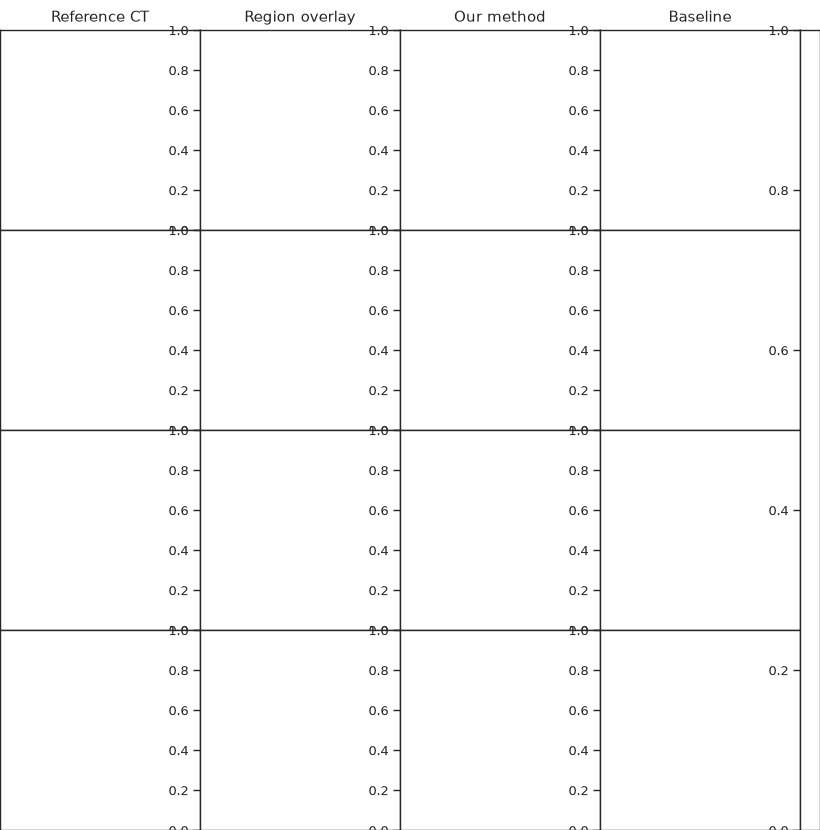

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import project.visual.matplotlib as mpl_viz

def compute_bbox(mask, margin=10):
    """Square crop in axes 0/1; ordinary bounding box along axis 2."""
    voxels = np.stack(np.nonzero(mask), axis=0)
    if voxels.shape[1] == 0:
        raise ValueError("Cannot crop an empty mask.")

    shape = np.asarray(mask.shape)
    lo = voxels.min(axis=1)
    hi = voxels.max(axis=1) + 1

    side = int((hi[:2] - lo[:2]).max() + 2 * margin)
    if side > shape[:2].min():
        raise ValueError("Square crop exceeds in-plane dimensions.")

    start = np.maximum(lo - margin, 0)
    stop = np.minimum(hi + margin, shape)
    start[:2] = np.clip(
        (lo[:2] + hi[:2] - side) // 2,
        0, shape[:2] - side,
    )
    stop[:2] = start[:2] + side
    return start, stop

def select_slice(lesion_mask, lung_mask, crop, criterion='area'):
    lung = lung_mask[crop] > 0
    lesion = (lesion_mask[crop] > 0) & lung
    n_lesion = lesion.sum(axis=(0, 1))
    n_lung = lung.sum(axis=(0, 1))

    if not n_lesion.any():
        raise ValueError("No lesion voxels in this crop.")

    if criterion == 'prevalence':
        scores = np.divide(
            n_lesion, n_lung,
            out=np.zeros(n_lung.shape, dtype=float),
            where=n_lung > 0,
        )
    elif criterion == 'area':
        scores = n_lesion
    else:
        raise ValueError("criterion must be 'prevalence' or 'area'.")

    return int(scores.argmax()) + crop[2].start

def _slice(vol, bbox, idx):
    lo, hi = bbox
    return vol[lo[0]:hi[0],lo[1]:hi[1],idx].T

def plot_clinical_grid(selections, criterion='prevalence'):
    fig, axes, cax = mpl_viz.subplot_grid(
        n_rows=len(selections),
        n_cols=4,
        ax_height=2,
        ax_width=2,
        spacing=0,
        padding=(0.0, 0.0, 0.0, 0.3),
        cbar_width=0.2
    )
    axes = np.asarray(axes).reshape(len(selections), 4)

    for ax, title in zip(axes[0], ['Reference CT', 'Region overlay', 'Our method', 'Baseline']):
        ax.set_title(title)

    norm = LogNorm(vmin=0.1, vmax=100)  # kPa
    selected_slices = []

    for row, (case_id, lesion_name) in enumerate(selections):
        mask = regions[case_id]['parenchyma']
        lesion = regions[case_id][lesion_name]
        img = images[case_id]
        ours = E_train[case_id]
        baseline = E_optim[case_id]

        if not all(v.shape == mask.shape for v in [img, lesion, ours, baseline]):
            raise ValueError(f"{case_id}: array shapes do not match.")

        bbox = compute_bbox(mask)
        crop = tuple(slice(a, b) for a, b in zip(*bbox))
        idx = select_slice(lesion, mask, crop, criterion)
        selected_slices.append((case_id, lesion_name, idx))

        ct_slice = _slice(img, bbox, idx)
        mask_slice = _slice(mask, bbox, idx)
        lesion_slice = _slice(lesion, bbox, idx)

        for ax in axes[row]:
            ax.imshow(
                ct_slice, origin='lower', cmap='gray',
                vmin=-1000, vmax=0, interpolation='nearest',
            )

        # Transparent background; orange lesion overlay.
        overlay = np.zeros((*lesion_slice.shape, 4))
        overlay[lesion_slice] = [1.0, 0.35, 0.0, 0.55]
        axes[row, 1].imshow(
            overlay, origin='lower', interpolation='nearest'
        )

        for col, volume in [(2, ours), (3, baseline)]:
            values = _slice(volume, bbox, idx) / 1000
            values = np.ma.masked_where(
                ~mask_slice | ~np.isfinite(values) | (values <= 0),
                values,
            )
            im = axes[row, col].imshow(
                values, origin='lower', cmap='turbo',
                norm=norm, interpolation='nearest',
            )
            axes[row, col].contour(
                lesion_slice.astype(float),
                levels=[0.5],
                colors='white',
                linewidths=0.8,
                origin='lower'
            )

        label = lesion_name.replace('_', ' ').capitalize()
        axes[row, 0].set_ylabel(f'{case_id}\n{label}')

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])

    cbar = fig.colorbar(im, cax=cax, extend='min')
    cbar.set_label('E (kPa)')
    cbar.set_ticks([0.1, 1, 10, 100])
    cbar.set_ticklabels(['0.1', '1', '10', '100'])

    return fig, axes, selected_slices

if eval_phase == 'val':
    selections = [
        ('unknown_39_1', 'ggo'),
        ('unknown_51_1', 'consolidation'),
        ('unknown_18_1', 'nodule'),
        ('unknown_27_1', 'emphysema'),
    ]
elif eval_phase == 'test':
    selections = [
        ('unknown_17_3', 'ggo'),
        ('unknown_17_1', 'consolidation'),
        ('unknown_29_1', 'nodule'),
        ('unknown_47_1', 'emphysema'),
    ]
else:
    selections = []

fig, axes, selected_slices = plot_clinical_grid(selections)
print(selected_slices)  # Original-volume slice indices
plt.pause(1.0)
fig

In [45]:
#fig.savefig('bmc_clinical_grid.png', bbox_inches='tight')
#fig.savefig('bmc_clinical_grid.pdf', bbox_inches='tight')

# BMC TV reg weight sweep

In [97]:
sweep_keys = ['params.tv_reg_weight']
setting_keys = protocol_keys + sweep_keys

optim_jobs = load_optim_jobs('../bmc-4dct/2026-11-16_optimize', *setting_keys)
train_jobs = load_train_jobs('../bmc-4dct/2026-11-16_train', *setting_keys)

optim_metrics = load_optim_metrics(optim_jobs)
train_metrics = load_train_metrics(train_jobs)

100%|██████████| 9/9 [00:00<00:00, 133.16it/s]


In [98]:
best_metrics, best_lookup = select_best_epoch(
    train_metrics, setting_keys, by='u_cell.nrmse'
)
display(best_lookup)

compare_metrics = concat_methods(
    best_metrics, optim_metrics, eval_phase, case_split
)
compare_metrics['subject'] = compare_metrics['num_voxels'].map(case_lookup)
compare_metrics['phase'] = compare_metrics['params.curr_phase']

params.random_seed  \
params.curr_phase params.material_type params.tv_reg_weight                       
0                 LE                   0.0001                                 0   
                                       0.0010                                 0   
                                       0.0100                                 0   

                                                             epoch  \
params.curr_phase params.material_type params.tv_reg_weight          
0                 LE                   0.0001                   23   
                                       0.0010                   23   
                                       0.0100                   24   

                                                             u_cell.nrmse  
params.curr_phase params.material_type params.tv_reg_weight                
0                 LE                   0.0001                    0.194769  
                                       0.0010                    0.195049  
                                       0.0100                    0.195820

In [99]:
def load_baseline(optim_jobs, case_id, *args):
    output_dir = Path(optim_jobs.loc[*args, case_id].work_dir) / 'outputs'
    path = output_dir / 'optimize' / 'default' / case_id / 'rasters' / 'E_pred.nii.gz'
    return project.fileio.load_nibabel(path).get_fdata(dtype=np.float32)

def load_trainer(train_jobs, best_lookup, case_ids, *args):
    import project.training
    best = best_lookup.loc[*args]
    best_seed = best['params.random_seed']
    output_dir = Path(train_jobs.loc[*args, best_seed].work_dir) / 'outputs'
    print(output_dir)
    config = resolve_bmc_config(case_ids, *args)
    examples = project.get_examples(config['dataset'])
    trainer = project.training.get_trainer(
        examples, config['training'], output_dir=output_dir, device='cuda'
    )
    trainer.load_checkpoint(epoch=int(best.epoch))
    return trainer

def run_inference(trainer, batch):
    outputs = trainer.run_batch(batch, eval_mode=True)
    return outputs['preds']['E'][0,0].detach().cpu().numpy()

In [100]:
%%time
import numpy as np

tv_reg_weights = (
    best_lookup.index.get_level_values('params.tv_reg_weight')
    .unique()
    .sort_values()
)

E_optim, E_train = {}, {}

for tv_reg_weight in tv_reg_weights:
    print(tv_reg_weight)

    setting_vals = (*protocol_vals, tv_reg_weight)
    E_optim[tv_reg_weight] = {}
    E_train[tv_reg_weight] = {}

    trainer = load_trainer(train_jobs, best_lookup, case_ids, *setting_vals)
    try:
        for batch in trainer.train_loader:
            case_id = batch['example'][0].subject
            print(case_id)

            # keep model predictions even if baseline output is missing
            E_train[tv_reg_weight][case_id] = run_inference(trainer, batch)

            try:
                E_optim[tv_reg_weight][case_id] = load_baseline(optim_jobs, case_id, *setting_vals)
            except FileNotFoundError as e:
                print(f'WARNING: {e}', file=sys.stderr)
    finally:
        del trainer

0.0001
/projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-16_train/job_6f122f283a512928/outputs
Loading ../bmc-4dct/2026-11-01_config.yaml
Gathering examples...
9 total
Splitting data examples
Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
backbone.encoder.unit0.conv.weight                 216	(8, 1, 3, 3, 3)
backbone.encoder.unit0.norm.weight                 8	(8,)
backbone.encoder.unit0.norm.bias                   8	(8,)
backbone.encoder.unit1.conv.weight                 1728	(8, 8, 3, 3, 3)
backbone.encoder.unit1.norm.weight                 8	(8,)
backbone.encoder.unit1.norm.bias                   8	(8,)
backbone.sublevel.encoder.unit0.conv.weight        3456	(16, 8, 3, 3, 3)
backbone.sublevel.encoder.unit0.norm.weight        16	(16,)
backbone.sublevel.encoder.unit0.norm.bias          16	(16,)
backbone.sublevel.encoder.unit1.conv.weight        6912	(16, 16, 3, 3, 3)
backbone.sublevel.encoder.unit1.norm.w

In [83]:
%%time
import pandas as pd

region_rows, rank_rows = [], []

for weight in tv_reg_weights:
    for method, predictions in [
        (optim_method, E_optim[weight]),
        (train_method, E_train[weight]),
    ]:
        for case_id, E in predictions.items():
            print(weight, method, case_id)
            metadata = dict(
                method=method, case_id=case_id, tv_reg_weight=weight
            )
            region_rows.extend(
                evaluate_regions(E, regions[case_id], **metadata)
            )
            rank_rows.append(
                evaluate_ranking(E, regions[case_id], **metadata)
            )

region_eval = pd.DataFrame(region_rows)
rank_eval = pd.DataFrame(rank_rows)

0.0001 Baseline unknown_15_1
0.0001 Baseline unknown_18_1
0.0001 Baseline unknown_19_1
0.0001 Baseline unknown_22_1
0.0001 Baseline unknown_27_1
0.0001 Baseline unknown_39_1
0.0001 Baseline unknown_40_1
0.0001 Baseline unknown_40_5
0.0001 Baseline unknown_51_1
0.0001 Ours unknown_15_1
0.0001 Ours unknown_18_1
0.0001 Ours unknown_19_1
0.0001 Ours unknown_22_1
0.0001 Ours unknown_27_1
0.0001 Ours unknown_39_1
0.0001 Ours unknown_40_1
0.0001 Ours unknown_40_5
0.0001 Ours unknown_51_1
0.001 Baseline unknown_15_1
0.001 Baseline unknown_18_1
0.001 Baseline unknown_19_1
0.001 Baseline unknown_22_1
0.001 Baseline unknown_27_1
0.001 Baseline unknown_39_1
0.001 Baseline unknown_40_1
0.001 Baseline unknown_40_5
0.001 Baseline unknown_51_1
0.001 Ours unknown_15_1
0.001 Ours unknown_18_1
0.001 Ours unknown_19_1
0.001 Ours unknown_22_1
0.001 Ours unknown_27_1
0.001 Ours unknown_39_1
0.001 Ours unknown_40_1
0.001 Ours unknown_40_5
0.001 Ours unknown_51_1
0.01 Baseline unknown_15_1
0.01 Baseline unkno

NameError: name 'pd' is not defined

In [85]:
import pandas as pd
region_eval = pd.DataFrame(region_rows)
rank_eval = pd.DataFrame(rank_rows)

In [89]:
rank_eval.groupby(['method', 'tv_reg_weight'])[['AUC_hard', 'AUC_soft']].agg(['mean', 'std', 'median'])

AUC_hard                      AUC_soft            \
                            mean       std    median      mean       std   
method   tv_reg_weight                                                     
Baseline 0.0001         0.445531  0.144281  0.474037  0.452573  0.119818   
         0.0010         0.476404  0.165302  0.496270  0.388272  0.105419   
         0.0100         0.516264  0.180558  0.572080  0.461254  0.159487   
Ours     0.0001         0.590050  0.067334  0.584963  0.616396  0.166071   
         0.0010         0.613666  0.069862  0.609613  0.597842  0.187442   
         0.0100         0.594628  0.060372  0.577526  0.614828  0.202089   

                                  
                          median  
method   tv_reg_weight            
Baseline 0.0001         0.454967  
         0.0010         0.394810  
         0.0100         0.509956  
Ours     0.0001         0.610352  
         0.0010         0.566079  
         0.0100         0.580058

In [101]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

def plot_tv_grid(selections, weights=None):
    # selections: [(case_id, lesion_name), ...]
    if weights is None:
        weights = sorted(E_train)

    fig, axes = plt.subplots(
        2 * len(selections), 1 + len(weights),
        figsize=(3 * (1 + len(weights)), 5 * len(selections)),
        squeeze=False,
        layout='constrained',
    )
    norm = LogNorm(vmin=0.1, vmax=100)  # kPa

    for i, (case_id, lesion_name) in enumerate(selections):
        masks = regions[case_id]
        lung = masks['parenchyma']
        lesion = masks[lesion_name]
        bbox = compute_bbox(lung)
        crop = tuple(slice(lo, hi) for lo, hi in zip(*bbox))
        z = select_slice(lesion, lung, crop, criterion='area')

        lung_slice = _slice(lung, bbox, z)
        lesion_slice = _slice(lesion, bbox, z)

        for j, (method, predictions) in enumerate([
            (train_method, E_train),
            (optim_method, E_optim),
        ]):
            row = 2 * i + j
            ax = axes[row, 0]
            ax.imshow(
                _slice(images[case_id], bbox, z),
                origin='lower', cmap='gray', vmin=-1000, vmax=0,
            )
            if lesion_slice.any() and not lesion_slice.all():
                ax.contour(
                    lesion_slice, levels=[0.5],
                    colors='cyan', linewidths=0.7,
                )
            ax.set_ylabel(f'{case_id}\n{lesion_name} · {method}')

            for col, weight in enumerate(weights, start=1):
                ax = axes[row, col]
                E = predictions[weight].get(case_id)
                if E is None:
                    ax.text(
                        0.5, 0.5, 'Missing', ha='center', va='center',
                        transform=ax.transAxes,
                    )
                    continue

                field = np.ma.masked_where(
                    ~lung_slice.astype(bool),
                    _slice(E, bbox, z) / 1000,
                )
                ax.imshow(
                    field, origin='lower', cmap='turbo', norm=norm,
                )
                if lesion_slice.any() and not lesion_slice.all():
                    ax.contour(
                        lesion_slice, levels=[0.5],
                        colors='cyan', linewidths=0.7,
                    )

    axes[0, 0].set_title('Reference CT')
    for col, weight in enumerate(weights, start=1):
        axes[0, col].set_title(f'TV = {weight:g}')

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])

    fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap='turbo'),
        ax=axes[:, 1:].ravel().tolist(),
        label='Young’s modulus (kPa)', shrink=0.8,
    )
    return fig, axes

fig, axes = plot_tv_grid(selections)

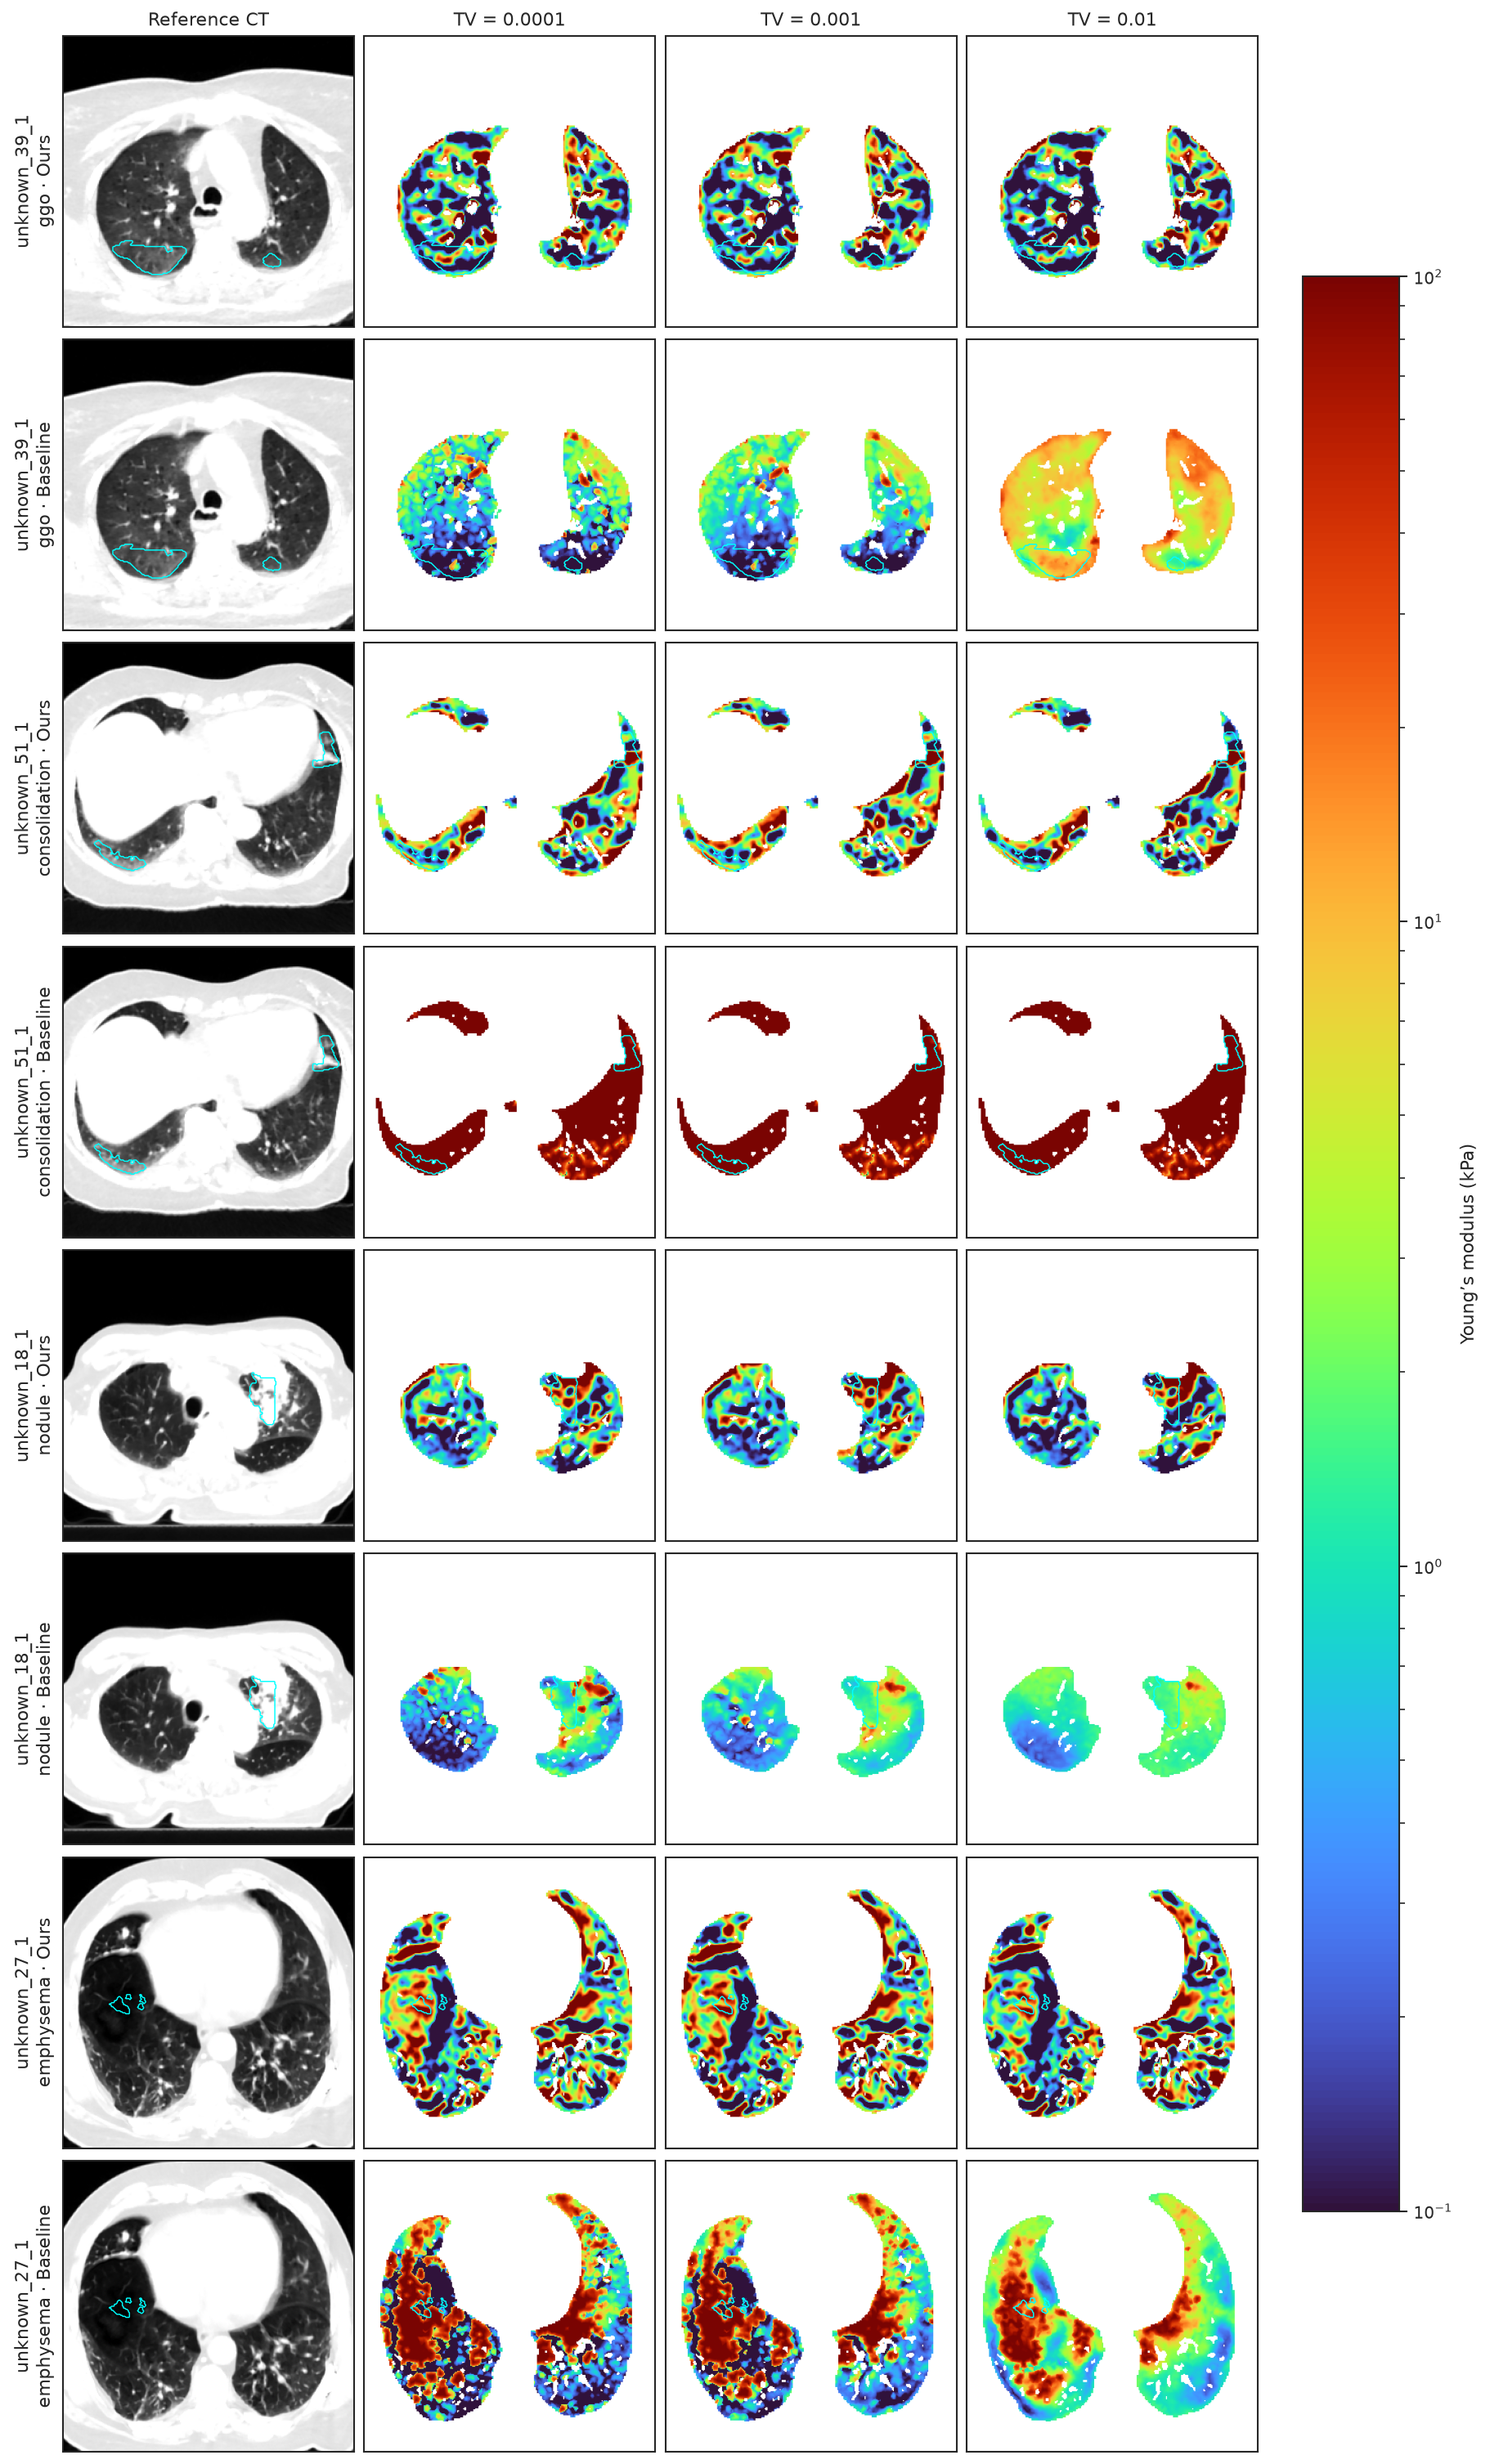

In [102]:
fig

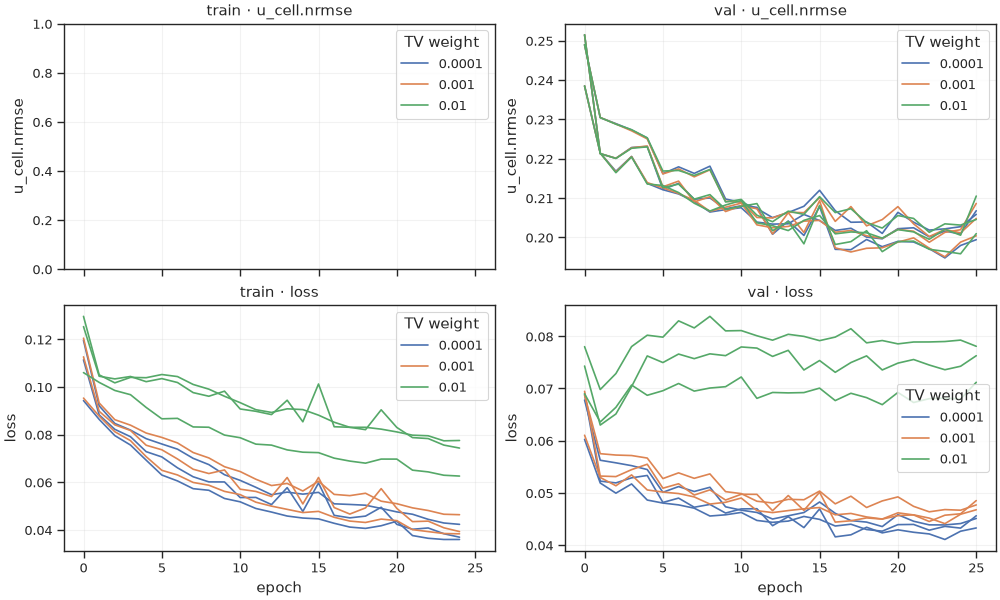

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

weight_key = 'params.tv_reg_weight'
df = train_metrics.loc[
    train_metrics['params.curr_phase'].eq(0)
    & train_metrics['params.material_type'].eq('LE')
].copy()

curves = (
    df.groupby([weight_key, 'params.random_seed', 'phase', 'epoch'])[
        ['u_cell.nrmse', 'loss']
    ]
    .mean()
    .reset_index()
)
curves['TV weight'] = curves[weight_key].map(lambda w: f'{w:g}')

fig, axes = plt.subplots(
    2, 2, figsize=(10, 6), sharex=True, layout='constrained'
)

for row, metric in enumerate(['u_cell.nrmse', 'loss']):
    for col, phase in enumerate(['train', 'val']):
        ax = axes[row, col]
        sns.lineplot(
            data=curves.loc[curves.phase.eq(phase)],
            x='epoch',
            y=metric,
            hue='TV weight',
            units='params.random_seed',
            estimator=None,
            ax=ax,
        )
        ax.set_title(f'{phase} · {metric}')
        ax.grid(alpha=0.25)

plt.show()

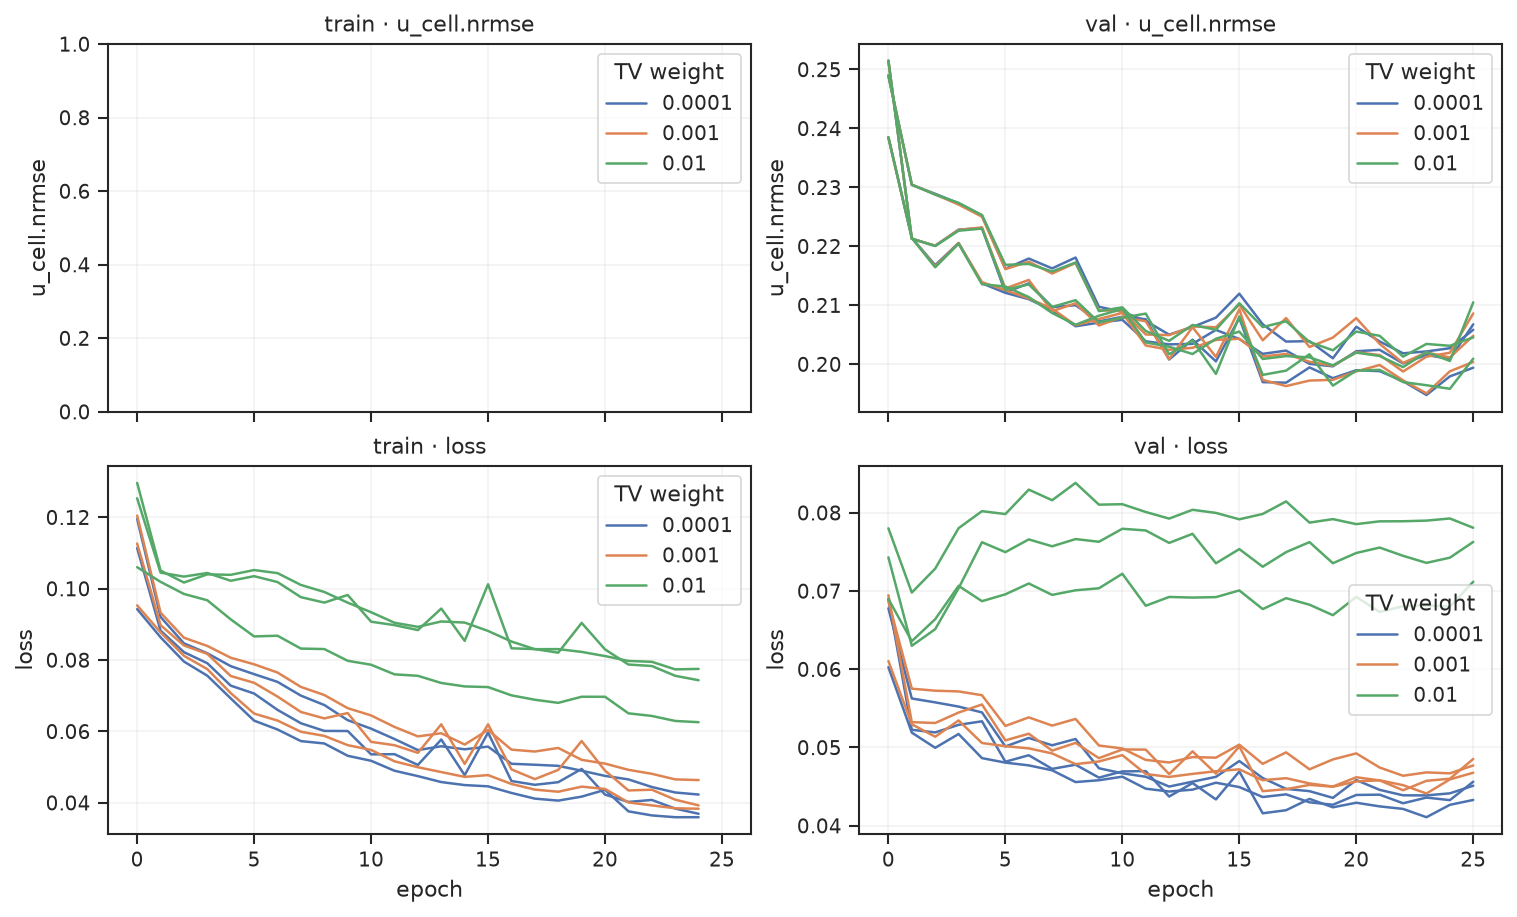

In [104]:
fig